In [1]:
import sys
import os
from pathlib import Path

# Get current working directory and find project root
# Assuming notebook is in lvmogp_ruby/ folder
cwd = Path.cwd()

# If we're in lvmogp_ruby, go up one level to project root
if cwd.name == "lvmogp_ruby":
    project_root = str(cwd.parent)
else:
    # Otherwise assume we're already at project root or need to go up
    project_root = str(cwd)

# Add project root to path (contains src/ folder)
if project_root not in sys.path:
    sys.path.insert(0, project_root)

print(f"Current directory: {cwd}")
print(f"Project root: {project_root}")

Current directory: c:\Users\mtret\MyStudy\conditional_overlaping_gaussian_processes\lvmogp_ruby
Project root: c:\Users\mtret\MyStudy\conditional_overlaping_gaussian_processes


In [2]:
import numpy as np
from lvmogp_ruby.ssvi_lvmogp import LVMOGP_SSVI
import pathlib as pl
import torch
import matplotlib.pyplot as plt

from lvmogp_ruby.lvmogp_test_functions import TestFun
        
        
        
torch.set_default_dtype(torch.float64)

# Quick Notebook Showing how to fit the LVMOGP

In [3]:
seed=1
surface_type = 'linear_relation'
n_new_points=20
n_new_funs = 10
data_type_name = f'two_observed_{n_new_funs}_new'
n_fun = 2 + n_new_funs
total_train = 30*2 + 3 * n_new_points
n_points = [10]*2 + [n_new_points]*n_new_funs
n_train = n_points

set_opt_seed = False

same_points = False
plot_figs = True

train_inducing = True
domain = [0, 2]
latent_dims = 2
latent_dims_lvmogp = 2
observed_dims = 1
max_points = 60

noise = 0.05
n_grid_points = 100
continuous_dims = ['x1', 'x2'][:observed_dims]
lengthscales_x = [0.3, 0.3]
lengthscales_h = [0.4, 0.4, 0.4, 0.4, 0.4, 0.4][:latent_dims]


test_fun = TestFun(domain=domain, seed=seed, n_fun=n_fun,
                   observed_dims=observed_dims, test_type=surface_type, latent_dims=latent_dims, max_points=max_points,
                   noise=noise, n_grid_points=n_grid_points, same_points=same_points, lengthscales_X=lengthscales_x,
                   lengthscales_H=lengthscales_h)

## Generate and Plot the Data

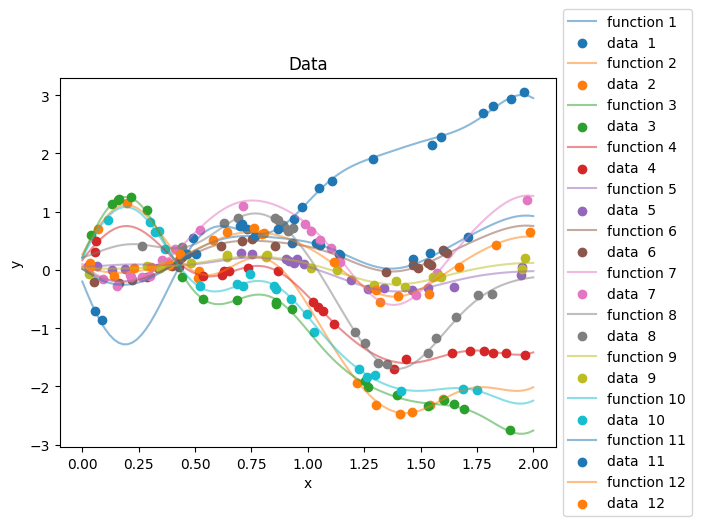

In [4]:
data_X, fun_nos, data_y = test_fun.create_data(n_points=n_points)


if plot_figs:
    test_fun.plot_data(n_points)

## Fit the LVMOGP

Randomly initialise the hyperparameters

In [10]:
torch.set_default_dtype(torch.float64)

# Random H initialisation (following original LVMOGP_demonstration.ipynb)
H_mean = torch.tensor(
    np.random.uniform(-1, 1, (n_fun, latent_dims_lvmogp)),
    dtype=torch.float64
)
# Use reasonable variance (not too small!) - original uses 1e-6 but that's too small for SSVI
H_var  = torch.ones_like(H_mean) * 0.1  # Start with 0.1 instead of 1e-6

# Likelihood noise (same formula as before)
lik_variance = np.var(data_y) * 0.01
n_inducing_points          =  32                     # number of inducing inputs

Make the LVMOGP

In [11]:
Y_torch  = torch.tensor(data_y, dtype=torch.float64)
X_torch  = torch.tensor(data_X, dtype=torch.float64)
fn_torch = torch.tensor(fun_nos, dtype=torch.long)  # Must be long for function IDs

# Determine dimensions
Q_x = X_torch.shape[1]  # Observed dimensions
Q_h = latent_dims_lvmogp  # Function latent dimensions
Q_total = Q_x + Q_h
M = Y_torch.shape[1]  # Output dimension

# Initialize inducing points in full space [Q_x + Q_h]
Vx = torch.randn(n_inducing_points, Q_total, dtype=torch.float64) * 0.5

# H_mean and H_var are per function (not per observation)
# H_mean already has shape (n_fun, Q_h)

model = LVMOGP_SSVI(
    X_data=X_torch,
    X_data_fn=fn_torch,
    num_fns=n_fun,
    Q_h=Q_h,
    M=M,
    Vx=Vx,
    H_data_mean=H_mean,
    H_data_var=H_var,
    sigma2=lik_variance,
    beta=[[1.0] * Q_total],  # Lengthscales for all dimensions
    sigma2_s=[1.0],  # Signal variance
    P=32,  # Number of SSVI samples
    trainable_V=True,
    encoder_hidden_dims=[128, 64],
    local_lr=0.0001,
    global_lr=0.0001,
    device="cuda" if torch.cuda.is_available() else "cpu",
    enable_missing_data=False
)


c:\Users\mtret\MyStudy\conditional_overlaping_gaussian_processes\venv\Lib\site-packages\torch\_compile.py:53: UserWarning: optimizer contains a parameter group with duplicate parameters; in future, this will cause an error; see github.com/pytorch/pytorch/issues/40967 for more information
  return disable_fn(*args, **kwargs)


In [17]:
# Training configuration (simple - no complex config objects needed)
class SimpleConfig:
    def __init__(self):
        self.device = "cuda" if torch.cuda.is_available() else "cpu"
        self.batch_size = min(128, len(data_X))
        self.total_iters = 250
        
cfg = SimpleConfig()
print(f"Training config: batch_size={cfg.batch_size}, total_iters={cfg.total_iters}, device={cfg.device}")


Training config: batch_size=128, total_iters=250, device=cpu


Train it

In [18]:
# Training loop (using train_step with batch-level ELBO tracking)
batch_size = cfg.batch_size
total_iters = cfg.total_iters
N = len(Y_torch)

# Store loss/ELBO for plotting
losses = []
iterations_list = []

model.train()

print(f"Starting training: {total_iters} iterations, batch_size={batch_size}")
print("=" * 60)

for iteration in range(total_iters):
    # Random batch (mini-batch SGD for SSVI)
    indices = torch.randperm(N, device=model.device)[:batch_size]
    Y_batch = Y_torch[indices]
    
    # Training step (returns loss = -ELBO)
    loss = model.train_step(Y_batch, indices)
    
    # Store loss periodically
    if (iteration + 1) % 5 == 0 or iteration == 0:
        losses.append(loss)
        iterations_list.append(iteration + 1)
    
    # Print progress
    if (iteration + 1) % 25 == 0 or iteration == 0:
        print(f"Iteration {iteration + 1}/{total_iters}: Loss = {loss:.4f}")

print("=" * 60)
print("Training completed!")
print(f"Final loss: {losses[-1]:.4f}")

# Store results in compatible format
results = {
    "loss": np.array(losses),
    "iterations": np.array(iterations_list),
    "H_mean": model.H_data_mean.mean(dim=0),  # Average over P samples [num_fns, Q_h]
    "H_log_s2": torch.log(model.H_data_var.mean(dim=0))  # Average over P samples
}

model.results = results  # Attach to model for compatibility

Starting training: 250 iterations, batch_size=128
Iteration 1/250: Loss = 84.3128
Iteration 25/250: Loss = 84.0648
Iteration 50/250: Loss = 88.2668
Iteration 75/250: Loss = 81.0165
Iteration 100/250: Loss = 80.1000
Iteration 125/250: Loss = 85.9009
Iteration 150/250: Loss = 73.1057
Iteration 175/250: Loss = 77.9529
Iteration 200/250: Loss = 67.3788
Iteration 225/250: Loss = 75.6615
Iteration 250/250: Loss = 78.8011
Training completed!
Final loss: 78.8011


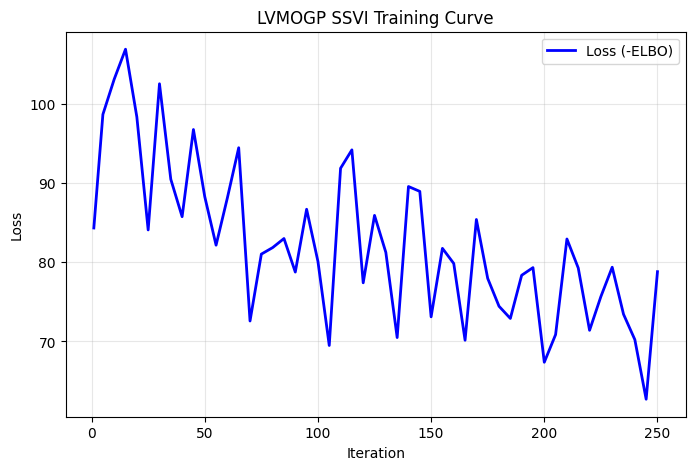

In [19]:
import matplotlib.pyplot as plt

# Plot training curve
loss_vals = results["loss"]
iterations = results["iterations"]

plt.figure(figsize=(8, 5))
plt.plot(iterations, loss_vals, label='Loss (-ELBO)', color='blue', linewidth=2)
plt.xlabel('Iteration')
plt.ylabel('Loss')
plt.title('LVMOGP SSVI Training Curve')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

Predict on new points

In [20]:
# Prepare test points for prediction (following original LVMOGP_demonstration structure)
device = model.device
x_new = torch.linspace(domain[0], domain[1], 100,
                       dtype=torch.get_default_dtype(), device=device).view(-1, 1)   # (100, 1)

# Create test points for all functions
xs_new = x_new.repeat(n_fun, 1)                                            # (100*n_fun, 1)

# Create function IDs for test points
fun_ids = torch.unique(fn_torch, sorted=True)                             # (n_fun,)
X_data_fun_new = torch.cat([torch.full((len(x_new),), fid,
                                      dtype=torch.long, device=device)
                           for fid in fun_ids])                            # (100*n_fun,)

# Make predictions using learned H representations
# predict_f automatically uses stored H_data_mean and H_data_var
lvm_mu, lvm_sig2 = model.predict_f(xs_new, X_data_fun_new)

Plot the predictions and the latent coordinates

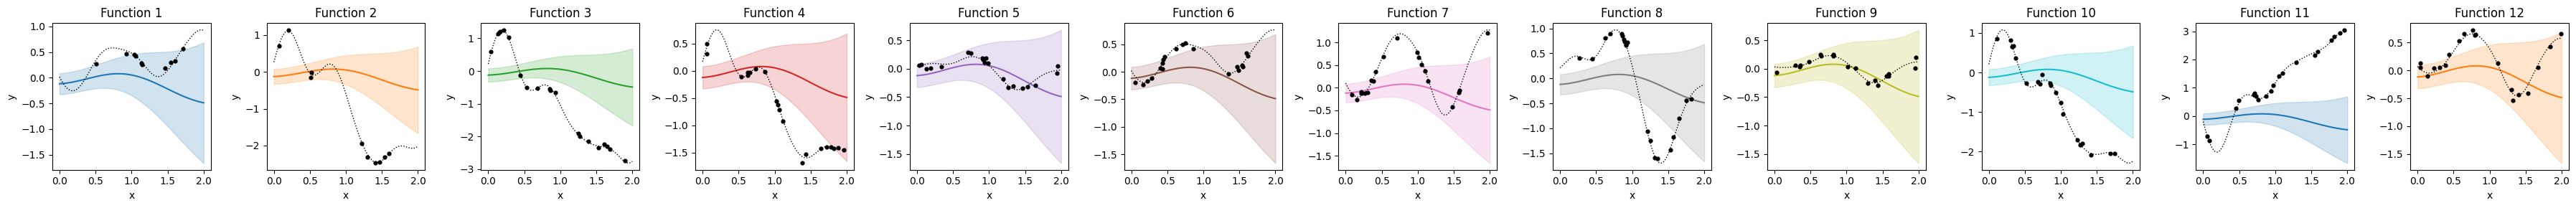

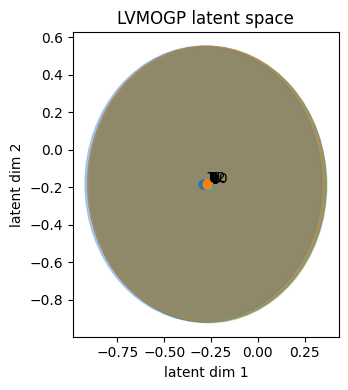

In [21]:
from matplotlib.patches import Ellipse
import numpy as np

# SETTINGS  
n_fun        = len(test_fun.functions)          # number of functions
pts_per_fun  = 100                              # x-points per function
palette      = (plt.rcParams['axes.prop_cycle']
                .by_key()['color']) * 10        # plenty of distinct colours

#  1. Ground-truth curves  
ys_new = []
for f in test_fun.functions:
    y_np, _ = f.predict_y(x_new.cpu().numpy())              # SimpleGP -> NumPy (already NumPy)
    ys_new.append(torch.from_numpy(y_np)                    # NumPy -> Torch
                       .to(dtype=x_new.dtype,
                           device=x_new.device))

#  2. LVMOGP predictions vs. ground-truth 
fig, axs = plt.subplots(1, ncols=n_fun, figsize=(3*n_fun, 3))
if n_fun == 1:
    axs = [axs]  # Make it iterable for single function case
else:
    axs = axs.flatten()

x_np   = x_new.cpu().numpy().flatten()                      # (100,)

lvm_mu_np = lvm_mu.cpu().numpy().squeeze()                  # (n_fun*100,)
lvm_sig2_np = lvm_sig2.cpu().numpy().squeeze()              # (n_fun*100,)

# Check if reshaping is valid
expected_size = n_fun * pts_per_fun
if lvm_mu_np.size != expected_size:
    print(f"Warning: Expected {expected_size} elements, got {lvm_mu_np.size}")
    pts_per_fun = lvm_mu_np.size // n_fun

mu_np = lvm_mu_np.reshape(n_fun, pts_per_fun)               # (n_fun, pts_per_fun)
s2_np = lvm_sig2_np.reshape(n_fun, pts_per_fun)

for i in range(n_fun):
    mu_i, s2_i = mu_np[i], s2_np[i]

    axs[i].plot(x_np[:pts_per_fun], mu_i, color=palette[i], lw=1.5)  # prediction
    axs[i].fill_between(x_np[:pts_per_fun],                          # 95 % CI
                        mu_i + 2.0*np.sqrt(np.maximum(s2_i, 1e-8)),  
                        mu_i - 2.0*np.sqrt(np.maximum(s2_i, 1e-8)),
                        alpha=0.20, color=palette[i])

    axs[i].scatter(test_fun.xs[i][:n_points[i]],            # training pts
                   test_fun.ys[i][:n_points[i]],
                   color='k', s=12, zorder=3)

    axs[i].plot(x_np[:pts_per_fun],                         # ground-truth
                ys_new[i].cpu().numpy().flatten()[:pts_per_fun],
                linestyle=':', color='k', lw=1)

    axs[i].set_title(f'Function {i+1}')
    axs[i].set_xlabel('x');  axs[i].set_ylabel('y')

plt.tight_layout();  plt.show()

#  3. Latent space (Q = 2)
fig, axH = plt.subplots(figsize=(4, 4))

H_mean_trained = model.results["H_mean"].cpu().numpy()     # (num_fns, Q)
H_var_trained = model.results["H_log_s2"].exp().cpu().numpy()  # (num_fns, Q)

H_mean_fun = H_mean_trained  # (n_fun, Q)
H_var_fun = H_var_trained    # (n_fun, Q)

for i, (m, v) in enumerate(zip(H_mean_fun, H_var_fun)):
    axH.scatter(m[0], m[1], color=palette[i], s=40, zorder=3) 
    
    offset = np.array([0.01, 0.01])
    axH.annotate(str(i+1), m + offset)

    width = 1.95 * np.sqrt(np.maximum(v[0], 1e-6))   # Avoid tiny ellipses
    height = 1.95 * np.sqrt(np.maximum(v[1], 1e-6))
    
    ell = Ellipse(xy=m,
                  width=width,
                  height=height,
                  angle=0,
                  alpha=0.30,
                  color=palette[i])
    axH.add_patch(ell)

axH.set_title('LVMOGP latent space')
axH.set_xlabel('latent dim 1')
axH.set_ylabel('latent dim 2')
axH.set_aspect('equal', adjustable='box')
plt.tight_layout()
plt.show()